# Model Testing — DadBod (Swing)

This notebook checks the DadBod Swing model. It **runs `dadbod_swing.ipynb` first** (so it always tests exactly the current code and settings), then:

| Section | Question it answers |
|---|---|
| A. Data checks | Did every source download? Is anything stale? Did Kalshi's automatic search find every race, and does it agree with the hand table? |
| B. Model sanity checks | Are the numbers internally consistent (probabilities 0–100%, shares add to 1, seat counts possible)? |
| C. Coverage by race | Which races rest on thin polling? |
| D. Disagreements with Kalshi | Where do the model and the market differ by a lot, and why? |
| E. Robustness | Which settings move the answer most? Does it hold up with the toggles on/off, different reliability rules, different random seeds? |
| F. Trajectory | How has the forecast moved week by week (backtests)? |
| G. Summary | One table of every check, saved to `Output/testing/` |

**Reading the checks:** each one is **PASS** (fine), **WARN** (worth a look, doesn't stop the model), or **FAIL** (something is broken; don't publish this run). Takes a minute or two (the sweep and trajectory re-run the model about 70 times with fewer simulations).

Note: you may need to restart the kernel to use updated packages.


run_all.py overrides: AS_OF_DATE = 2026-10-26, N_SIMS = 10,000


**margin** = (10·r·polls + 5·fundamentals + 1·Kalshi) / (10·r + 5 + 1)
- With plenty of polls (r ≈ 1): polls 62%, fundamentals 31%, Kalshi 6%
- r = poll reliability from the model's own error sizes (1 poll → 45%, 3 → 71%, 9 → 88%)
- fundamentals = 2024 state margin + national swing ± 3 incumbency, where national swing = (2·generic ballot + 1·approval margin) / 3 − 2024 national margin (R+1.5)
- polls = last 28 days, recency weight 1.0 → 0.25; LV:RV:A = 1:0.9:0.8; sample size (n/800)^0.5 capped at 2,500; flooding 1/k^0.5; partisan shift 3 pts; house effects on; ungraded pollsters random
- national signals: VoteHub polls + Kalshi averages counted as 5 polls
- uncertainty: source errors correlated (ρ = 0.3); 10,000 simulations; backtest as of 2026-10-26

repo root: /mnt/attach/outputs/repo | outputs -> /mnt/attach/outputs/repo/Models/DadBod_Model/DadBod_Swing/Output


votehub_senate_cache.csv: API unavailable (URLError); using saved copy with 95 rows


...

kalshi_national_cache.csv: API unavailable (ValueError); using saved copy with 11 rows
Kalshi: 35/35 races found (0 by title search); 0 differ from the hand table; nominees from Kalshi for 34/35 races, 0 differ from the hand table (details in Model Testing)
State polls: 95 general-election polls -> 89 in the last 28 days -> 89 with the nominees
As of 2026-10-26: generic ballot D+9.7, net approval -21.8 -> approval margin D+7.6
Fundamentals: national_mood_now = +9.00, swing_since_2024 = +10.48
Ungraded pollsters: 31 (49 of 89 polls) get a random VoteHub grade in each of the 10,000 simulations


,VoteHub polls,n polls,effective n,Kalshi average,Kalshi counts as,combined
signal,,,,,,
"generic ballot (D-R, two-party)",9.23,5,4.10,10.05,5,9.68
net approval,-22.34,5,4.24,-21.40,5,-21.83


P(Democrats hold at least 51 seats): 58.3%
Predicted Democratic seats (mean):   51.2   (median 51, 80% range 48-55)


,P(D >= 51),D seats (mean),as of
model,,,
DadBod (Swing) — this run,58.3%,51.2,2026-10-26
"DadBod (Swing), Kalshi weight 0",57.3%,51.2,2026-10-26
Kalshi alone (control market / sum of race odds),63.5%,51.7,2026-10-26
Model 1 (Full Configs),64.6%,51.5,2026-10-26
Ozempic (Swing),58.5%,51.2,2026-10-26
Ozempic (Literal),48.2%,50.5,2026-10-26
DadBod (Literal),46.6%,50.3,2026-10-26


,inc,2024,n_polls,n_eff,r,polls,fund,kalshi_margin,share_polls,share_fund,share_kalshi,final,sd,P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,,,,,,,,,,,,
Massachusetts,D / running,D+25.2,2,2.0,62%,D+29.4,D+38.7,D+11.3,51%,41%,8%,D+31.7,5.2,100%,98%,2%,Safe D
Rhode Island,D / running,D+13.8,1,1.0,45%,D+24.8,D+27.3,D+12.8,43%,48%,10%,D+24.8,5.6,100%,98%,1%,Safe D
Oregon,D / running,D+14.3,0,0.0,0%,-,D+27.8,D+15.4,0%,83%,17%,D+25.7,6.8,100%,98%,2%,Safe D
Delaware,D / running,D+14.7,0,0.0,0%,-,D+28.2,D+15.2,0%,83%,17%,D+26.0,6.8,100%,98%,2%,Safe D
Colorado,D / running,D+11.0,0,0.0,0%,-,D+24.5,D+15.3,0%,83%,17%,D+22.9,6.8,100%,98%,2%,Safe D
Illinois,D / open,D+10.9,2,1.8,59%,D+15.6,D+21.4,D+11.2,50%,42%,8%,D+17.6,5.2,100%,98%,2%,Safe D
New Mexico,D / running,D+6.0,1,1.0,45%,D+17.7,D+19.5,D+11.4,43%,48%,10%,D+18.0,5.7,99%,97%,2%,Safe D
Virginia,D / running,D+5.8,0,0.0,0%,-,D+19.3,D+15.4,0%,83%,17%,D+18.6,6.8,99%,98%,1%,Safe D
New Jersey,D / running,D+5.9,0,0.0,0%,-,D+19.4,D+14.5,0%,83%,17%,D+18.6,6.8,99%,97%,2%,Safe D


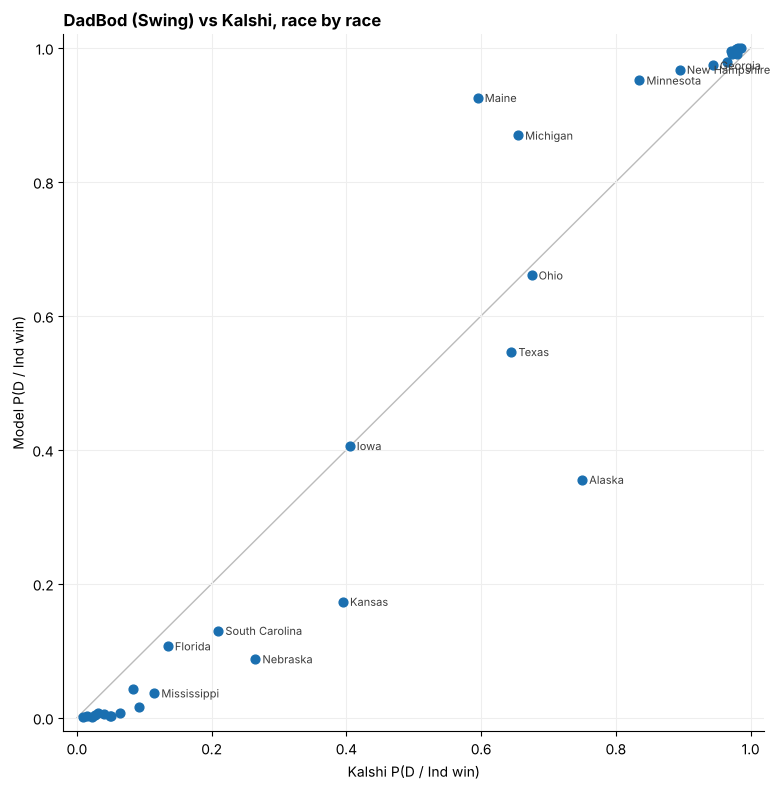

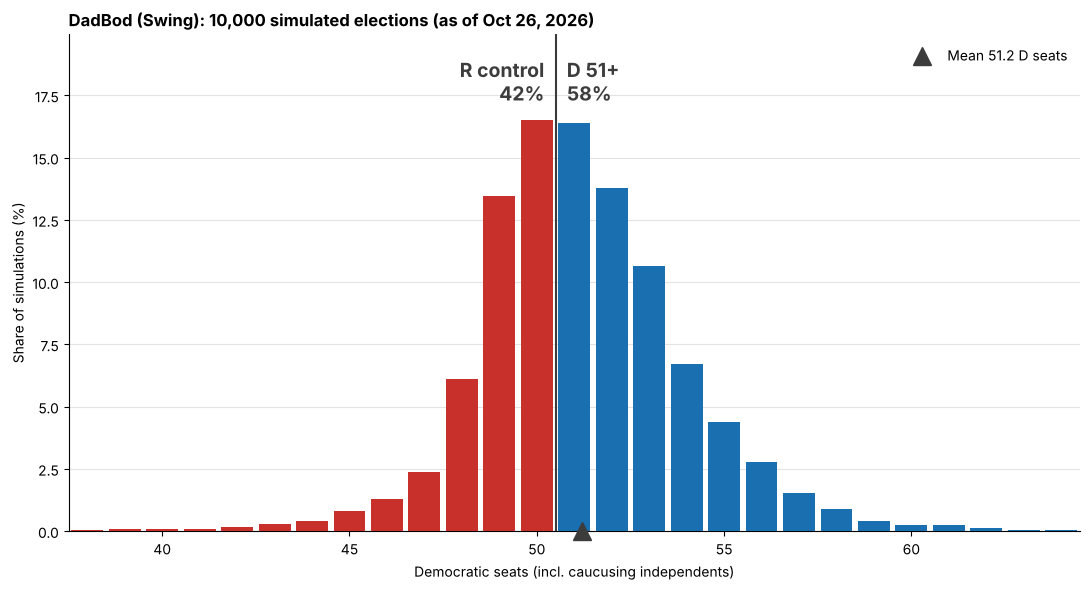

Saved race_table.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, headline.json to /mnt/attach/outputs/repo/Models/DadBod_Model/DadBod_Swing/Output
Standard export -> /mnt/attach/outputs/repo/Models/DadBod_Model/DadBod_Swing/Output/standard


In [1]:
%run ./dadbod_swing.ipynb

In [2]:
TEST_DIR = S["OUT_DIR"] / "testing"
TEST_DIR.mkdir(parents=True, exist_ok=True)
CHECKS = []


def check(section, name, status, detail):
    """Record one check. status: PASS / WARN / FAIL."""
    CHECKS.append({"section": section, "check": name, "status": status, "detail": detail})


def show(section):
    t = pd.DataFrame([c for c in CHECKS if c["section"] == section])
    display(t.drop(columns="section").style.map(
        lambda v: {"PASS": "background-color:#DFF0D8", "WARN": "background-color:#FCF8E3", "FAIL": "background-color:#F2DEDE"}.get(v, ""),
        subset=["status"]) if len(t) else t)


SIM_N = 3000 # simulations per re-run in sections E and F (fewer than the main run, for speed)
r, polls, env, today = RES["races"], RES["polls"], RES["env"], RES["today"]

## A. Data checks
- **Sources:** each download should say *live*. *cache* means the website was unreachable and the last saved copy was used.
- **Freshness:** the newest state poll should be under 7 days old and the newest national poll under 21 days. Election-week polling is frequent, so older usually means the feed is lagging.
- **Kalshi search vs the hand table:** the search finds markets by title. Any race where it found a *different* market from the hand table, or fell back to the table, is listed.
- **Nominees:** taken from Kalshi's candidate names. Any disagreement with the hand table is listed (a nominee change, or a name Kalshi spells differently).

In [3]:
for name, stat in SOURCE_STATUS.items():
    check("A", f"source: {name}", "PASS" if stat == "live" else "WARN", stat)

newest = DATA["senate"]["end_date"].max()
age = (today - newest).days
check("A", "newest state poll", "PASS" if age <= 7 else "WARN", f"{newest:%Y-%m-%d} ({age} days old)")
for nm, df in [("generic ballot", DATA["generic"]), ("approval", DATA["approval"])]:
    d = df.loc[df["Date"] <= today, "Date"].max()
    a = (today - d).days
    check("A", f"newest {nm} poll (VoteHub)", "PASS" if a <= 21 else "WARN",
          f"{d:%Y-%m-%d} ({a} days old){' - Kalshi averages fill the gap' if a > 21 else ''}")
fk = DATA["kalshi_races"]["fetched"].iloc[0] if "fetched" in DATA["kalshi_races"] else "?"
check("A", "Kalshi race prices date", "PASS" if str(fk) == pd.Timestamp.today().strftime("%Y-%m-%d") else "WARN", f"fetched {fk}")

kc = KALSHI_CHECK
missing = kc.index[kc["found_event"].isna()].tolist()
check("A", "Kalshi races found", "PASS" if not missing else "FAIL", f"{kc['found_event'].notna().sum()}/35" + (f"; missing {missing}" if missing else ""))
fb = kc.index[kc["found_by"] == "fallback table"].tolist()
check("A", "Kalshi races found by title search", "PASS" if not fb else "WARN", "all" if not fb else f"used hand table for {fb}")
diff = kc[~kc["matches_hand_table"] & kc["found_event"].notna()]
check("A", "Kalshi search agrees with hand table", "PASS" if diff.empty else "WARN",
      "all 35 agree" if diff.empty else "; ".join(f"{s}: found {a}, table {b}" for s, (a, b) in diff[["found_event", "fallback_table"]].iterrows()))
nd = NOMINEE_CHECK[~NOMINEE_CHECK["matches_hand_table"]]
check("A", "nominees agree with hand table", "PASS" if nd.empty else "WARN",
      "all 35 agree" if nd.empty else "; ".join(f"{s}: {row['republican']} vs {row['opposition']}" for s, row in nd.iterrows()))
part = NOMINEE_CHECK.index[NOMINEE_CHECK["source"] != "Kalshi"].tolist()
check("A", "nominees from Kalshi names", "PASS" if len(part) <= 1 else "WARN",
      f"{35 - len(part)}/35 from Kalshi; hand table used for {part} (Kalshi lists party names there)")

raw_window = DATA["senate"][(today - DATA["senate"]["end_date"]).dt.days.between(0, CONFIG["WINDOW_DAYS"])]
dropped = len(raw_window) - len(polls)
check("A", "polls dropped for missing nominees", "PASS" if dropped <= 0.1 * max(len(raw_window), 1) else "WARN",
      f"{dropped} of {len(raw_window)} polls in the window (old hypothetical match-ups)")
if len(polls):
    sh = polls.loc[polls["unrated"], "weight"].sum() / polls["weight"].sum()
    check("A", "weight from ungraded pollsters", "PASS" if sh < 0.5 else "WARN",
          f"{polls['unrated'].sum()} of {len(polls)} polls, {sh:.0%} of poll weight ({CONFIG['UNRATED_POLLSTERS']} grades)")
for sig, row in env["table"].iterrows():
    n = row["n polls"]
    check("A", f"national: {sig}", "PASS" if row["effective n"] >= 3 or row["Kalshi counts as"] > 0 else "WARN",
          f"{n:.0f} VoteHub polls (effective {row['effective n']:.1f}) + Kalshi counted as {row['Kalshi counts as']:.0f} -> {row['combined']:+.1f}")
check("A", "undecided share U used for Kalshi approval", "PASS" if 0 <= env["U"] <= 10 else "WARN", f"U = {env['U']:.1f} pts")
show("A")

,check,status,detail
0,source: votehub_senate_cache.csv,WARN,cache (URLError)
1,source: votehub_generic_ballot_cache.csv,WARN,cache (URLError)
2,source: votehub_approval_cache.csv,WARN,cache (URLError)
3,source: kalshi_races_cache.csv,WARN,cache (URLError)
4,source: kalshi_national_cache.csv,WARN,cache (ValueError)
5,newest state poll,PASS,2026-10-22 (4 days old)
6,newest generic ballot poll (VoteHub),WARN,2026-10-04 (22 days old) - Kalshi averages fill the gap
7,newest approval poll (VoteHub),PASS,2026-10-06 (20 days old)
8,Kalshi race prices date,PASS,fetched 2026-10-26
9,Kalshi races found,PASS,35/35


## B. Model sanity checks
Internal consistency: these should always PASS. A FAIL means a bug, not a data problem.

In [4]:
p_ok = r["p_dem"].between(0, 1).all() and r["kalshi_p"].dropna().between(0, 1).all()
check("B", "probabilities between 0 and 1", "PASS" if p_ok else "FAIL", "race and Kalshi probabilities")
shares = (r["share_polls"] + r["share_fund"] + r["share_kalshi"] - 1).abs().max()
check("B", "source shares add to 100%", "PASS" if shares < 1e-9 else "FAIL", f"max error {shares:.1e}")
check("B", "no missing race margins", "PASS" if r["post_mean"].notna().all() and r["post_sd"].gt(0).all() else "FAIL", "post_mean / post_sd")
ds = RES["d_seats"]
check("B", "seat counts possible", "PASS" if ds.min() >= S["HOLDOVER_D"] and ds.max() <= S["HOLDOVER_D"] + 35 else "FAIL",
      f"range {ds.min()}-{ds.max()} (possible {S['HOLDOVER_D']}-{S['HOLDOVER_D'] + 35})")
exp_from_races = S["HOLDOVER_D"] + sum(p * S["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st, p in r["p_dem"].items())
gap = abs(exp_from_races - RES["summary"]["exp_d_seats"])
check("B", "mean seats = sum of race probabilities", "PASS" if gap < 0.15 else "WARN", f"{RES['summary']['exp_d_seats']:.2f} vs {exp_from_races:.2f}")
p = RES["summary"]["p_d_51"]
se = np.sqrt(p * (1 - p) / CONFIG["N_SIMS"])
check("B", "simulation noise on P(51+)", "PASS" if se < 0.01 else "WARN", f"±{1.96 * se:.1%} (95% range) with {CONFIG['N_SIMS']:,} simulations")
check("B", "reliability between 0 and 1", "PASS" if r["reliability"].between(0, 1).all() else "FAIL", f"range {r['reliability'].min():.2f}-{r['reliability'].max():.2f}")
show("B")

,check,status,detail
0,probabilities between 0 and 1,PASS,race and Kalshi probabilities
1,source shares add to 100%,PASS,max error 1.1e-16
2,no missing race margins,PASS,post_mean / post_sd
3,seat counts possible,PASS,range 35-68 (possible 34-69)
4,mean seats = sum of race probabilities,PASS,51.21 vs 51.21
5,simulation noise on P(51+),PASS,"±1.0% (95% range) with 10,000 simulations"
6,reliability between 0 and 1,PASS,range 0.00-0.90


## C. Coverage by race
Races where the forecast leans on thin evidence. **WARN** = a race Kalshi gives between 15% and 85% (so it could matter for control) with fewer than 3 effective polls or a newest poll over 14 days old.

In [5]:
cov = pd.DataFrame({"n_polls": r["n_polls"], "effective n": r["n_eff"].round(1), "reliability r": r["reliability"].round(2),
                    "newest poll (days)": r["last_poll_age"], "share from polls": r["share_polls"].round(2),
                    "model P": r["p_dem"].round(2), "Kalshi P": r["kalshi_p"].round(2)})
contested = cov["Kalshi P"].between(0.15, 0.85)
thin = contested & ((cov["effective n"] < 3) | (cov["newest poll (days)"].fillna(999) > 14))
cov["flag"] = np.where(thin, "thin + contested", "")
for st in cov.index[thin]:
    check("C", f"coverage: {st}", "WARN", f"{cov.loc[st, 'n_polls']} polls (effective {cov.loc[st, 'effective n']}), Kalshi {cov.loc[st, 'Kalshi P']:.0%}")
if not thin.any():
    check("C", "coverage of contested races", "PASS", "every race Kalshi rates 15-85% has 3+ effective recent polls")
display(cov.sort_values("Kalshi P", ascending=False))
cov.to_csv(TEST_DIR / "coverage.csv")

,n_polls,effective n,reliability r,newest poll (days),share from polls,model P,Kalshi P,flag
State,,,,,,,,
Illinois,2,1.8,0.59,6.0,0.50,1.00,0.98,
Delaware,0,0.0,0.00,NaN,0.00,1.00,0.98,
Colorado,0,0.0,0.00,NaN,0.00,1.00,0.98,
Rhode Island,1,1.0,0.45,18.0,0.43,1.00,0.98,
Virginia,0,0.0,0.00,NaN,0.00,0.99,0.98,
Oregon,0,0.0,0.00,NaN,0.00,1.00,0.98,
Massachusetts,2,2.0,0.62,9.0,0.51,1.00,0.98,
New Jersey,0,0.0,0.00,NaN,0.00,0.99,0.97,
North Carolina,7,5.6,0.82,6.0,0.58,0.98,0.97,


## D. Disagreements with Kalshi
Races where the model and Kalshi differ by more than 25 points. These aren't errors: they're the races worth discussing (candidate quality, late events, or polls the market doesn't believe).

In [6]:
dis = pd.DataFrame({"model P": r["p_dem"], "Kalshi P": r["kalshi_p"], "gap": r["p_dem"] - r["kalshi_p"],
                    "polls": r["poll_mean"].map(margin_label), "fundamentals": r["fund_mean"].map(margin_label),
                    "final": r["post_mean"].map(margin_label)})
big = dis[dis["gap"].abs() > 0.25].sort_values("gap")
for st, row in big.iterrows():
    check("D", f"model vs Kalshi: {st}", "WARN", f"model {row['model P']:.0%} vs Kalshi {row['Kalshi P']:.0%} (polls {row['polls']}, fundamentals {row['fundamentals']})")
if big.empty:
    check("D", "model vs Kalshi", "PASS", "no race differs by more than 25 points")
display(big.style.format({"model P": "{:.0%}", "Kalshi P": "{:.0%}", "gap": "{:+.0%}"}) if len(big) else "No large disagreements.")

,model P,Kalshi P,gap,polls,fundamentals,final
State,,,,,,
Alaska,36%,75%,-39%,D+0.7,R+5.7,R+1.6
Maine,93%,60%,+33%,D+1.4,D+14.4,D+6.2


## E. Robustness

### E1. Sensitivity sweep
Changes **one setting at a time** (everything else stays at its CONFIG value) and re-runs with 3,000 simulations and the same random seed. Longer bars in the tornado chart = settings the answer depends on more. Edit `SWEEP_PARAMS` to test other values.

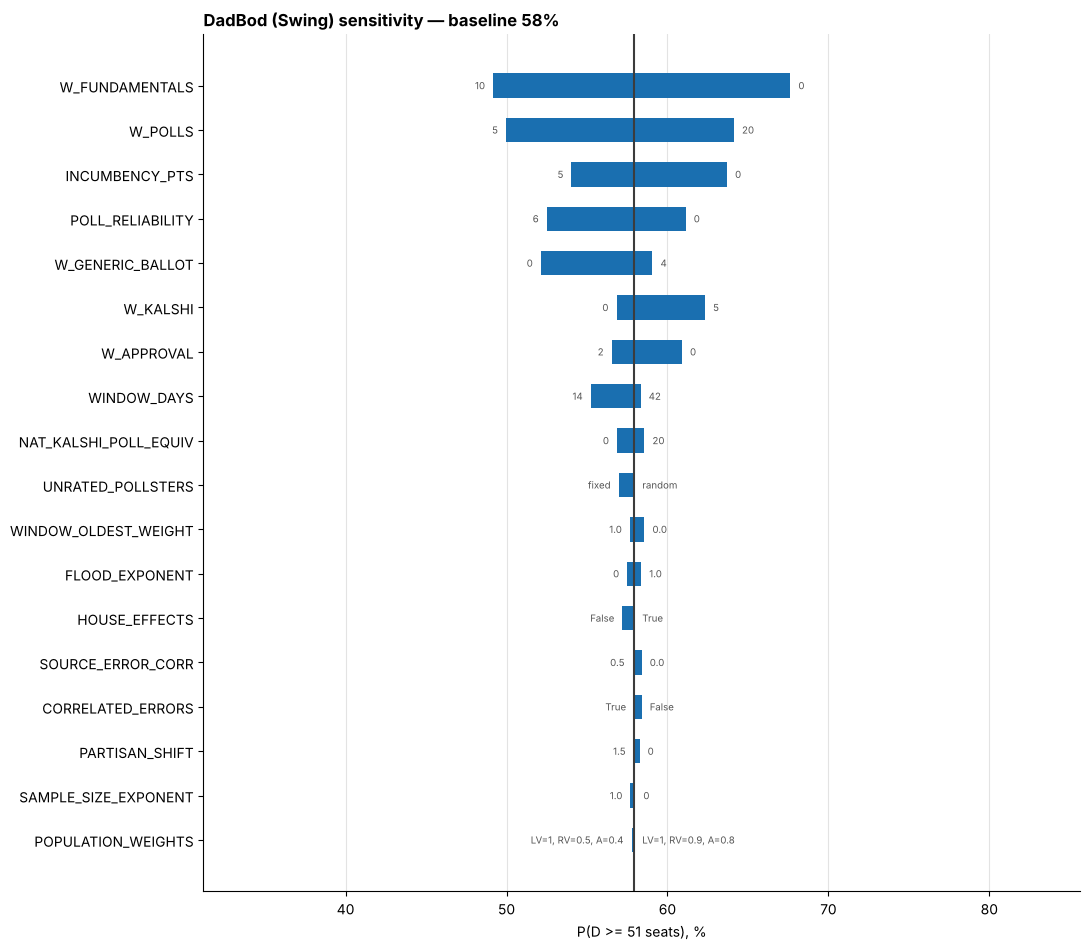

In [7]:
SWEEP_PARAMS = {
    "W_POLLS": [5, 10, 20],
    "W_FUNDAMENTALS": [0, 2.5, 5, 10],
    "W_KALSHI": [0, 1, 3, 5],
    "POLL_RELIABILITY": ["auto", 0, 1, 3, 6],
    "WINDOW_DAYS": [14, 21, 28, 42],
    "WINDOW_OLDEST_WEIGHT": [0.0, 0.25, 0.5, 1.0],
    "POPULATION_WEIGHTS": [{"LV": 1.0, "RV": v, "A": v - 0.1} for v in (0.5, 0.75, 0.9, 1.0)],
    "SAMPLE_SIZE_EXPONENT": [0, 0.25, 0.5, 1.0],
    "FLOOD_EXPONENT": [0, 0.5, 1.0],
    "PARTISAN_SHIFT": [0, 1.5, 3, 5],
    "HOUSE_EFFECTS": [False, True],
    "UNRATED_POLLSTERS": ["fixed", "random"],
    "NAT_KALSHI_POLL_EQUIV": [0, 2, 5, 10, 20],
    "W_GENERIC_BALLOT": [0, 1, 2, 4],
    "W_APPROVAL": [0, 1, 2],
    "INCUMBENCY_PTS": [0, 1.5, 3, 5],
    "CORRELATED_ERRORS": [False, True],
    "SOURCE_ERROR_CORR": [0.0, 0.15, 0.3, 0.5],
}


def value_label(v):
    return ", ".join(f"{k}={x:g}" for k, x in v.items()) if isinstance(v, dict) else str(v)


base = run_model(DATA, CONFIG, n_sims=SIM_N, verbose=False)["summary"]
rows = []
for key, values in SWEEP_PARAMS.items():
    for v in values:
        res = run_model(DATA, {**copy.deepcopy(CONFIG), key: v}, n_sims=SIM_N, verbose=False)["summary"]
        rows.append({"param": key, "value": value_label(v), "is_default": v == CONFIG[key], "p_d_51": res["p_d_51"], "exp_d_seats": res["exp_d_seats"]})
sweep = pd.DataFrame(rows)
sweep.to_csv(TEST_DIR / "sensitivity_sweep.csv", index=False)

rng_ = sweep.groupby("param")["p_d_51"].agg(["min", "max"])
lo = sweep.loc[sweep.groupby("param")["p_d_51"].idxmin()].set_index("param")["value"]
hi = sweep.loc[sweep.groupby("param")["p_d_51"].idxmax()].set_index("param")["value"]
rng_ = rng_.assign(span=rng_["max"] - rng_["min"]).sort_values("span")
fig, ax = plt.subplots(figsize=(11, 0.45 * len(rng_) + 1.5))
y = np.arange(len(rng_))
ax.barh(y, 100 * rng_["span"], left=100 * rng_["min"], height=0.55, color="#1A6FB0", zorder=3)
ax.axvline(100 * base["p_d_51"], color="#3C3C3C", lw=1.5, zorder=4)
for i, (prm, rr) in enumerate(rng_.iterrows()):
    ax.text(100 * rr["min"] - 0.5, i, lo[prm], ha="right", va="center", fontsize=7, color="#555555")
    ax.text(100 * rr["max"] + 0.5, i, hi[prm], ha="left", va="center", fontsize=7, color="#555555")
ax.set_yticks(y, rng_.index)
ax.set_xlabel("P(D >= 51 seats), %")
ax.grid(axis="x", color="#E3E3E3", zorder=0)
ax.spines[["right", "top"]].set_visible(False)
ax.set_title(f"DadBod (Swing) sensitivity — baseline {base['p_d_51']:.0%}", loc="left", fontweight="bold")
ax.set_xlim(max(0, 100 * rng_["min"].min() - 18), min(100, 100 * rng_["max"].max() + 18))
fig.tight_layout()
fig.savefig(TEST_DIR / "sensitivity_tornado.png", dpi=200, bbox_inches="tight")
plt.show()
top = rng_.sort_values("span", ascending=False).head(3)
check("E", "most influential settings", "PASS", "; ".join(f"{k}: {v['min']:.0%}-{v['max']:.0%}" for k, v in top.iterrows()))

### E2. The two on/off toggles
`HOUSE_EFFECTS` changes each poll's *margin*; `CORRELATED_ERRORS` changes each race's *uncertainty*. They're independent, so all four combinations are valid. This table shows how much each combination matters.

In [8]:
rows = []
for he in (False, True):
    for ce in (False, True):
        res = run_model(DATA, {**CONFIG, "HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce}, n_sims=SIM_N, verbose=False)
        comp = res["races"]
        rows.append({"HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce, "P(D >= 51)": res["summary"]["p_d_51"],
                     "D seats": res["summary"]["exp_d_seats"], "avg race sd": comp["post_sd"].mean(),
                     "P(D) Maine": comp.loc["Maine", "p_dem"], "P(D) Texas": comp.loc["Texas", "p_dem"]})
toggles = pd.DataFrame(rows)
toggles.to_csv(TEST_DIR / "toggles.csv", index=False)
display(toggles.style.format({"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "avg race sd": "{:.2f}", "P(D) Maine": "{:.0%}", "P(D) Texas": "{:.0%}"}))
spread = toggles["P(D >= 51)"].max() - toggles["P(D >= 51)"].min()
check("E", "toggle combinations agree", "PASS" if spread < 0.05 else "WARN", f"P(51+) spread {spread:.1%} across the 4 combinations")

,HOUSE_EFFECTS,CORRELATED_ERRORS,P(D >= 51),D seats,avg race sd,P(D) Maine,P(D) Texas
0,False,False,57.4%,51.1,5.11,94%,54%
1,False,True,57.2%,51.2,5.73,92%,54%
2,True,False,58.4%,51.2,5.11,94%,55%
3,True,True,57.9%,51.2,5.73,91%,55%


### E3. Simulation noise and random seeds
Re-runs the full model with 5 different random seeds. If P(51+) jumps around by more than a point or two, raise `N_SIMS`.

In [9]:
seed0 = S["SEED"]
seed_rows = []
for sd in [seed0, 1, 7, 42, 99]:
    S["SEED"] = sd
    res = run_model(DATA, CONFIG, verbose=False)["summary"]
    seed_rows.append({"seed": sd, "P(D >= 51)": res["p_d_51"], "D seats": res["exp_d_seats"]})
S["SEED"] = seed0
seeds = pd.DataFrame(seed_rows)
display(seeds.style.format({"P(D >= 51)": "{:.1%}", "D seats": "{:.2f}"}))
rg = seeds["P(D >= 51)"].max() - seeds["P(D >= 51)"].min()
check("E", "stable across random seeds", "PASS" if rg < 0.02 else "WARN", f"P(51+) range {rg:.1%} over 5 seeds at {CONFIG['N_SIMS']:,} simulations")

,seed,P(D >= 51),D seats
0,2026,58.3%,51.21
1,1,57.6%,51.17
2,7,57.5%,51.18
3,42,57.4%,51.14
4,99,57.4%,51.16


## F. Trajectory: the forecast week by week
Re-runs the model **as of** each Monday since September 1 (backtests). Each run uses only the polls that had been *released* by that date and **that day's Kalshi race prices**; the national numbers use polls only. The dashed line is Kalshi's own P(Democrats win the Senate) on the same dates.

*Note:* the first time this runs, it downloads Kalshi's daily price history (one request per market, ~30 seconds) and saves it to `Data_Cache/`.

kalshi_history_cache.csv: API unavailable (URLError); using saved copy with 105 rows


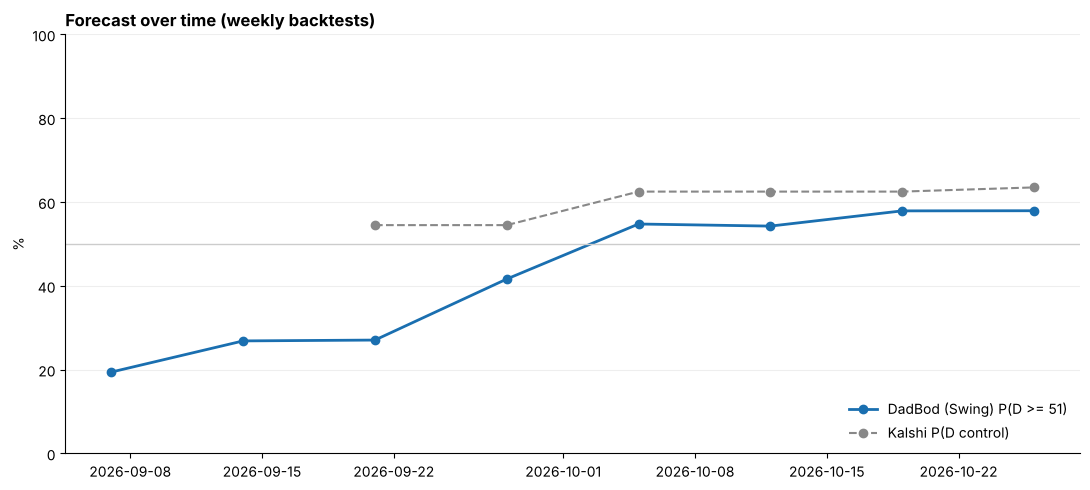

,P(D >= 51),D seats,Kalshi P(control),polls used
date,,,,
2026-09-07 00:00:00,19.4%,49.1,nan%,0
2026-09-14 00:00:00,26.9%,49.7,nan%,0
2026-09-21 00:00:00,27.1%,49.7,54.5%,0
2026-09-28 00:00:00,41.6%,50.3,54.5%,11
2026-10-05 00:00:00,54.8%,51.1,62.5%,34
2026-10-12 00:00:00,54.3%,51.1,62.5%,52
2026-10-19 00:00:00,57.9%,51.2,62.5%,81
2026-10-26 00:00:00,57.9%,51.2,63.5%,89


In [10]:
dates = list(pd.date_range("2026-09-07", today - pd.Timedelta(days=1), freq="W-MON")) + [today]
traj = []
for d in dates:
    res = run_model(DATA, {**CONFIG, "AS_OF_DATE": None if d == today else d.strftime("%Y-%m-%d")}, n_sims=SIM_N, verbose=False)
    kt = res["kalshi"]
    traj.append({"date": d, "P(D >= 51)": res["summary"]["p_d_51"], "D seats": res["summary"]["exp_d_seats"],
                 "Kalshi P(control)": float(kt.loc["CONTROL", "p_opp"]) if "CONTROL" in kt.index else np.nan,
                 "polls used": len(res["polls"])})
traj = pd.DataFrame(traj).set_index("date")
traj.to_csv(TEST_DIR / "trajectory.csv")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(traj.index, 100 * traj["P(D >= 51)"], marker="o", color="#1A6FB0", lw=2, label="DadBod (Swing) P(D >= 51)")
ax.plot(traj.index, 100 * traj["Kalshi P(control)"], marker="o", color="#888888", lw=1.5, ls="--", label="Kalshi P(D control)")
ax.axhline(50, color="#CCCCCC", lw=1)
ax.set_ylim(0, 100)
ax.set_ylabel("%")
ax.grid(axis="y", color="#EEEEEE")
ax.spines[["right", "top"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Forecast over time (weekly backtests)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(TEST_DIR / "trajectory.png", dpi=200, bbox_inches="tight")
plt.show()
display(traj.style.format({"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "Kalshi P(control)": "{:.1%}"}))
jump = traj["P(D >= 51)"].diff().abs().max()
check("F", "week-to-week stability", "PASS" if jump < 0.15 else "WARN", f"largest weekly move {jump:.0%}")

## G. Summary of every check
Saved to `Output/testing/checks.csv`. Before publishing a run, make sure there are no FAILs and that you understand every WARN.

In [11]:
summary = pd.DataFrame(CHECKS)
summary.to_csv(TEST_DIR / "checks.csv", index=False)
counts = summary["status"].value_counts()
print(f"{counts.get('PASS', 0)} PASS | {counts.get('WARN', 0)} WARN | {counts.get('FAIL', 0)} FAIL")
display(summary.style.map(
    lambda v: {"PASS": "background-color:#DFF0D8", "WARN": "background-color:#FCF8E3", "FAIL": "background-color:#F2DEDE"}.get(v, ""),
    subset=["status"]))

24 PASS | 13 WARN | 0 FAIL


,section,check,status,detail
0,A,source: votehub_senate_cache.csv,WARN,cache (URLError)
1,A,source: votehub_generic_ballot_cache.csv,WARN,cache (URLError)
2,A,source: votehub_approval_cache.csv,WARN,cache (URLError)
3,A,source: kalshi_races_cache.csv,WARN,cache (URLError)
4,A,source: kalshi_national_cache.csv,WARN,cache (ValueError)
5,A,newest state poll,PASS,2026-10-22 (4 days old)
6,A,newest generic ballot poll (VoteHub),WARN,2026-10-04 (22 days old) - Kalshi averages fill the gap
7,A,newest approval poll (VoteHub),PASS,2026-10-06 (20 days old)
8,A,Kalshi race prices date,PASS,fetched 2026-10-26
9,A,Kalshi races found,PASS,35/35
